# Неделя 26. Финальный проект и защита

**Практикум · Tech Orda · Gizatov A. S.**

Два занятия по 90 минут: 72 минуты теории и 108 минут практики за неделю.
Выполняйте ячейки последовательно через **Restart Kernel → Run All**.
Все обязательные вычисления работают на CPU без сети и API-ключей.

**Результат:** завершить работающий ML baseline от паспорта данных до CLI inference; защитить выбор метрики, threshold и ограничения.

**Завершенный учебный проект:** прогноз SLA breach на синтетических заявках. Локальная модель действительно обучается; результаты не являются оценкой реального helpdesk и не доказывают бизнес-эффект.


In [1]:
from pathlib import Path
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Работает из корня репозитория, папки недели и подпапок practice/homework.
_here = Path.cwd().resolve()
ROOT = next(p for p in [_here, *_here.parents] if (p / "course_plan.json").exists())
WEEK = ROOT / "week_26_final_project"
DATA = WEEK / "datasets"
SEED = 126
rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "font.size": 10})
print("Локальный CPU-режим; данные:", DATA.name)


Локальный CPU-режим; данные: datasets


## 1. Проблема, пользователь и критерий успеха

Координатор хочет расставить приоритеты заявок. Предсказываем eventual breach_sla по информации, известной при triage. Цена пропуска нарушения выше цены лишней проверки; условно FN=5, FP=1. Эти коэффициенты — допущения кейса, их нужно согласовать в реальном проекте.


In [2]:
df = pd.read_csv(DATA / 'service_tickets.csv', parse_dates=['opened_at'])
assert df.ticket_id.is_unique and df.opened_at.is_monotonic_increasing
assert not df.isna().any().any()
display(df.describe(include='all'))
print('Доля нарушения SLA:', df.breach_sla.mean())


,ticket_id,opened_at,minutes_open,affected_users,category,channel,breach_sla,final_resolution_minutes
count,600,600,600.000000,600.000000,600,600,600.00000,600.000000
unique,600,NaN,NaN,NaN,4,3,NaN,NaN
top,P0001,NaN,NaN,NaN,billing,portal,NaN,NaN
freq,1,NaN,NaN,NaN,157,207,NaN,NaN
mean,NaN,2026-01-25 23:00:00,59.403333,23.150000,NaN,NaN,0.30000,112.493333
min,NaN,2026-01-01 00:00:00,0.000000,1.000000,NaN,NaN,0.00000,10.000000
25%,NaN,2026-01-13 11:30:00,30.750000,13.000000,NaN,NaN,0.00000,48.750000
50%,NaN,2026-01-25 23:00:00,60.000000,23.000000,NaN,NaN,0.00000,89.000000
75%,NaN,2026-02-07 10:30:00,90.000000,34.000000,NaN,NaN,1.00000,165.000000
max,NaN,2026-02-19 22:00:00,120.000000,45.000000,NaN,NaN,1.00000,320.000000


Доля нарушения SLA: 0.3


## 2. EDA и leakage audit

`final_resolution_minutes` известна после закрытия заявки и почти прямо определяет target; использовать ее нельзя. ID также не включаем. Проверим риск по открытым на момент triage признакам, не заявляя причинность.


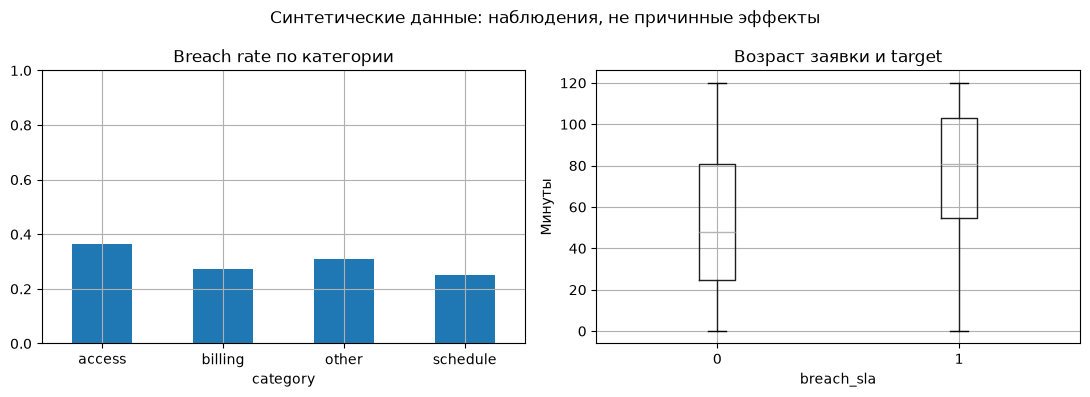

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
df.groupby('category').breach_sla.mean().plot.bar(ax=axes[0], rot=0, ylim=(0, 1), title='Breach rate по категории')
df.boxplot(column='minutes_open', by='breach_sla', ax=axes[1])
axes[1].set(title='Возраст заявки и target', xlabel='breach_sla', ylabel='Минуты')
plt.suptitle('Синтетические данные: наблюдения, не причинные эффекты'); plt.tight_layout(); plt.show()
FEATURES = ['minutes_open', 'affected_users', 'category', 'channel']
assert 'final_resolution_minutes' not in FEATURES and 'ticket_id' not in FEATURES


## 3. Временное разделение

Первые 60% — train, следующие 20% — validation, последние 20% — test. Это демонстрирует сценарий прогноза будущих заявок. Данные сгенерированы стационарно, поэтому эксперимент не моделирует реальный drift.


In [4]:
train, valid, test = df.iloc[:360].copy(), df.iloc[360:480].copy(), df.iloc[480:].copy()
assert train.opened_at.max() < valid.opened_at.min() < test.opened_at.min()
assert set(train.ticket_id).isdisjoint(test.ticket_id)
display(pd.DataFrame([{'split': name, 'n': len(part), 'positive_rate': part.breach_sla.mean(),
                       'start': part.opened_at.min(), 'end': part.opened_at.max()}
                      for name, part in [('train', train), ('validation', valid), ('test', test)]]))


,split,n,positive_rate,start,end
0,train,360,0.294444,2026-01-01,2026-01-30 22:00:00
1,validation,120,0.300000,2026-01-31,2026-02-09 22:00:00
2,test,120,0.316667,2026-02-10,2026-02-19 22:00:00


## 4. Baseline перед сложной моделью

DummyClassifier оценивает постоянный прогноз. Логистическая регрессия с Pipeline масштабирует числовые признаки и кодирует категории только на train. Не запускаем preprocess.fit на полном датасете.


In [5]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import average_precision_score, roc_auc_score, log_loss, precision_score, recall_score, f1_score, confusion_matrix
preprocess = ColumnTransformer([
    ('num', StandardScaler(), ['minutes_open', 'affected_users']),
    ('cat', OneHotEncoder(handle_unknown='ignore'), ['category', 'channel']),
])
model = Pipeline([('prepare', preprocess), ('model', LogisticRegression(C=1, max_iter=400, random_state=SEED))])
model.fit(train[FEATURES], train.breach_sla)
dummy = DummyClassifier(strategy='prior').fit(train[FEATURES], train.breach_sla)
va_prob = model.predict_proba(valid[FEATURES])[:, 1]
dummy_prob = dummy.predict_proba(valid[FEATURES])[:, 1]
display(pd.DataFrame([
    {'model': 'dummy_prior', 'validation_AP': average_precision_score(valid.breach_sla, dummy_prob), 'validation_log_loss': log_loss(valid.breach_sla, dummy_prob)},
    {'model': 'logistic_pipeline', 'validation_AP': average_precision_score(valid.breach_sla, va_prob), 'validation_log_loss': log_loss(valid.breach_sla, va_prob)},
]))


,model,validation_AP,validation_log_loss
0,dummy_prior,0.30000,0.610938
1,logistic_pipeline,0.51129,0.536437


## 5. Порог выбирается по validation

      Учебная стоимость $C=5\,FN+1\,FP$. Порог 0.5 не является универсально лучшим.
      Порог и относительную цену ошибок фиксируем до итогового test. Выбор по маленькой validation
      выборке шумный; при реальном внедрении нужно проверить устойчивость и business cost.


,threshold,cost,fn,fp,recall,precision
0,0.05,84,0,84,1.000000,0.300000
1,0.10,77,1,72,0.972222,0.327103
2,0.15,71,2,61,0.944444,0.357895
3,0.20,74,6,44,0.833333,0.405405
4,0.25,67,7,32,0.805556,0.475410
5,0.30,71,10,21,0.722222,0.553191
6,0.35,98,16,18,0.555556,0.526316
7,0.40,122,21,17,0.416667,0.468750
8,0.45,133,25,8,0.305556,0.578947
9,0.50,155,30,5,0.166667,0.545455


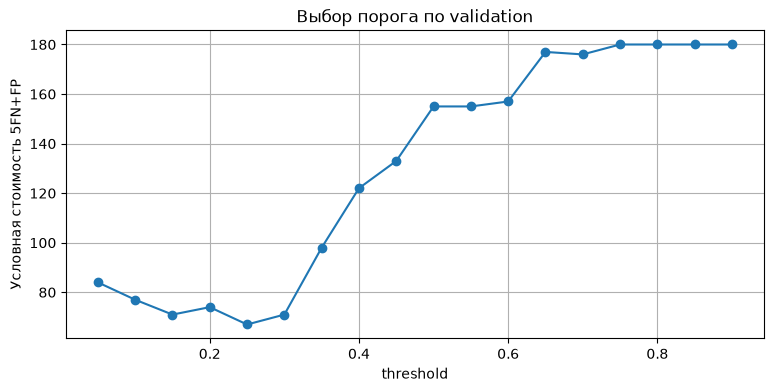

In [6]:
def cost_report(y, prob, threshold):
    pred = (prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {'threshold': threshold, 'cost': int(5*fn + fp), 'fn': int(fn), 'fp': int(fp),
            'recall': recall_score(y, pred, zero_division=0), 'precision': precision_score(y, pred, zero_division=0)}
thresholds = pd.DataFrame([cost_report(valid.breach_sla, va_prob, t) for t in np.linspace(.05, .9, 18)])
best = thresholds.sort_values(['cost', 'threshold']).iloc[0]
threshold = float(best.threshold)
display(thresholds)
thresholds.plot(x='threshold', y='cost', marker='o', legend=False, title='Выбор порога по validation')
plt.ylabel('Условная стоимость 5FN+FP'); plt.show()


## 6. Открываем test один раз

Фиксируем pipeline и threshold. Отчитываемся о ranking quality (AP, ROC-AUC), probabilistic quality (log loss) и decision quality (precision/recall/cost). Они отвечают на разные вопросы.


In [7]:
te_prob = model.predict_proba(test[FEATURES])[:, 1]
final = {'test_AP': average_precision_score(test.breach_sla, te_prob),
         'test_ROC_AUC': roc_auc_score(test.breach_sla, te_prob),
         'test_log_loss': log_loss(test.breach_sla, te_prob),
         **cost_report(test.breach_sla, te_prob, threshold)}
display(pd.Series(final))
assert np.isfinite(te_prob).all() and ((te_prob >= 0) & (te_prob <= 1)).all()
print('После этого test не используется для изменения threshold.')


test_AP           0.578613
test_ROC_AUC      0.699294
test_log_loss     0.567150
threshold         0.250000
cost             96.000000
fn               13.000000
fp               31.000000
recall            0.657895
precision         0.446429
dtype: float64

После этого test не используется для изменения threshold.


## 7. Анализ ошибок и срезов

Покажем ложные отрицательные заявки и recall по category. Малые группы дают нестабильные метрики; нулевой знаменатель нужно обозначать, а не скрывать. Наблюдаемая связь не доказывает, что изменение категории уменьшит риск.


In [8]:
predictions = test[['ticket_id', 'category', 'minutes_open', 'affected_users', 'breach_sla']].copy()
predictions['probability'] = te_prob
predictions['prediction'] = (te_prob >= threshold).astype(int)
display(predictions[(predictions.breach_sla == 1) & (predictions.prediction == 0)].head(8))
slices = []
for group, rows in predictions.groupby('category'):
    positives = rows.breach_sla.sum()
    slices.append({'category': group, 'n': len(rows), 'positives': int(positives),
                   'recall': recall_score(rows.breach_sla, rows.prediction, zero_division=0) if positives else np.nan})
display(pd.DataFrame(slices))


,ticket_id,category,minutes_open,affected_users,breach_sla,probability,prediction
483,P0484,other,33,37,1,0.214895,0
495,P0496,schedule,43,26,1,0.148328,0
521,P0522,other,28,40,1,0.210525,0
527,P0528,other,53,23,1,0.212014,0
542,P0543,schedule,60,21,1,0.168065,0
554,P0555,schedule,0,20,1,0.058828,0
555,P0556,billing,58,9,1,0.177686,0
556,P0557,schedule,27,27,1,0.114282,0


,category,n,positives,recall
0,access,31,14,0.857143
1,billing,26,7,0.571429
2,other,43,10,0.600000
3,schedule,20,7,0.428571


## 8. Ограниченная bootstrap-оценка

При фиксированной модели bootstrap test-строк дает приближенный интервал метрики. Здесь synthetic records независимы. Для связанных пользователей/временных рядов простой row bootstrap не подходит; используйте групповой или временной метод.


In [9]:
bootstrap = []
y_test = test.breach_sla.to_numpy()
for _ in range(150):
    ids = rng.integers(0, len(test), len(test))
    if len(np.unique(y_test[ids])) == 2:
        bootstrap.append(average_precision_score(y_test[ids], te_prob[ids]))
low, high = np.quantile(bootstrap, [.025, .975])
print(f'Примерный percentile interval для test AP: [{low:.3f}, {high:.3f}]')
assert 0 <= low <= high <= 1


Примерный percentile interval для test AP: [0.419, 0.733]


## 9. Inference-контракт

Новая заявка содержит только признаки triage. Проверим крайние значения и неизвестную категорию. Encoder может технически обработать новое значение, но это не означает, что прогноз вне обученного домена надежен.


In [10]:
sample = pd.DataFrame([{'minutes_open': 50, 'affected_users': 10, 'category': 'access', 'channel': 'portal'}])
risk = float(model.predict_proba(sample)[0, 1])
print({'risk': round(risk, 4), 'threshold': threshold, 'needs_review': risk >= threshold})
assert list(sample.columns) == FEATURES
assert (sample[['minutes_open', 'affected_users']] >= 0).all().all()
print('CLI: python capstone_cli.py --minutes-open 50 --affected-users 10 --category access --channel portal')


{'risk': 0.194, 'threshold': 0.25, 'needs_review': False}
CLI: python capstone_cli.py --minutes-open 50 --affected-users 10 --category access --channel portal


## 10. Защита проекта

Соседний PROJECT_TEMPLATE.md задает problem/data/split/metrics/demo/limitations. CLI обучает компактный baseline на локальных данных и выдает прогноз; он не выполняет облачный deployment. Защита должна объяснять практическую границу результата, а не только красивую цифру.


In [11]:
assert (WEEK / 'practice' / 'capstone_cli.py').exists()
print({'baseline': 'trained_locally', 'test': 'evaluated', 'cloud_deployment': 'not_run', 'data': 'synthetic'})


{'baseline': 'trained_locally', 'test': 'evaluated', 'cloud_deployment': 'not_run', 'data': 'synthetic'}


## Источники и следующий шаг

- [scikit-learn: common pitfalls](https://scikit-learn.org/stable/common_pitfalls.html)
- [scikit-learn: model evaluation](https://scikit-learn.org/stable/modules/model_evaluation.html)
- [scikit-learn: model persistence](https://scikit-learn.org/stable/model_persistence.html)

Откройте Markdown-задание в папке `../homework/` своей недели. Перед сдачей перезапустите ядро и убедитесь, что выводы соответствуют фактическим результатам.
